In [1]:
from pathlib import Path
import json
import gc

import numpy as np
import pandas as pd

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.0.6
NumPy: 2.5.3


In [2]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = None

    for path in [CURRENT_DIR, *CURRENT_DIR.parents]:
        if (
            (path / "data" / "processed").is_dir()
            and (path / "data" / "splits").is_dir()
        ):
            PROJECT_ROOT = path
            break

    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            f"Could not locate H-IDS project root from: {CURRENT_DIR}"
        )

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"

FINAL_DATA_PATH = (
    PROCESSED_DATA_DIR /
    "cic_ids2017_cleaned_deduplicated.parquet"
)

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset:")
print(FINAL_DATA_PATH)

print("\nDataset exists:", FINAL_DATA_PATH.exists())

Project root:
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS

Dataset:
c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\data\processed\cic_ids2017_cleaned_deduplicated.parquet

Dataset exists: True


In [3]:
train_ids = pd.read_csv(
    SPLITS_DIR / "train_indices.csv"
)["row_id"].to_numpy()

val_ids = pd.read_csv(
    SPLITS_DIR / "validation_indices.csv"
)["row_id"].to_numpy()

test_ids = pd.read_csv(
    SPLITS_DIR / "test_indices.csv"
)["row_id"].to_numpy()

print("Split sizes:")
print(f"Train:      {len(train_ids):,}")
print(f"Validation: {len(val_ids):,}")
print(f"Test:       {len(test_ids):,}")

Split sizes:
Train:      2,016,638
Validation: 252,080
Test:       252,080


In [4]:
with open(
    SPLITS_DIR / "label_mapping.json",
    "r",
    encoding="utf-8"
) as f:
    label_mapping_data = json.load(f)

print("Binary label mapping:")
print(label_mapping_data["binary"])

Binary label mapping:
{'0': 'BENIGN', '1': 'ATTACK'}


In [5]:
import pyarrow.parquet as pq

parquet_file = pq.ParquetFile(FINAL_DATA_PATH)

schema_columns = parquet_file.schema.names

print("Number of columns:", len(schema_columns))

print("\nFirst 10 columns:")
for column in schema_columns[:10]:
    print(column)

print("\nLast 5 columns:")
for column in schema_columns[-5:]:
    print(column)

Number of columns: 79

First 10 columns:
Destination Port
Flow Duration
Total Fwd Packets
Total Backward Packets
Total Length of Fwd Packets
Total Length of Bwd Packets
Fwd Packet Length Max
Fwd Packet Length Min
Fwd Packet Length Mean
Fwd Packet Length Std

Last 5 columns:
Idle Mean
Idle Std
Idle Max
Idle Min
Label


In [6]:
FEATURE_COLUMNS = [
    column
    for column in schema_columns
    if column != "Label"
]

print("Number of feature columns:", len(FEATURE_COLUMNS))

print("\nFeature columns:")
for i, column in enumerate(FEATURE_COLUMNS, start=1):
    print(f"{i:2}. {column}")

Number of feature columns: 78

Feature columns:
 1. Destination Port
 2. Flow Duration
 3. Total Fwd Packets
 4. Total Backward Packets
 5. Total Length of Fwd Packets
 6. Total Length of Bwd Packets
 7. Fwd Packet Length Max
 8. Fwd Packet Length Min
 9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Length Std
15. Flow Bytes/s
16. Flow Packets/s
17. Flow IAT Mean
18. Flow IAT Std
19. Flow IAT Max
20. Flow IAT Min
21. Fwd IAT Total
22. Fwd IAT Mean
23. Fwd IAT Std
24. Fwd IAT Max
25. Fwd IAT Min
26. Bwd IAT Total
27. Bwd IAT Mean
28. Bwd IAT Std
29. Bwd IAT Max
30. Bwd IAT Min
31. Fwd PSH Flags
32. Bwd PSH Flags
33. Fwd URG Flags
34. Bwd URG Flags
35. Fwd Header Length
36. Bwd Header Length
37. Fwd Packets/s
38. Bwd Packets/s
39. Min Packet Length
40. Max Packet Length
41. Packet Length Mean
42. Packet Length Std
43. Packet Length Variance
44. FIN Flag Count
45. SYN Flag Count
46. RST Flag 

In [8]:
label_schema = pq.read_table(
    FINAL_DATA_PATH,
    columns=["Label"]
)

label_sample = label_schema.to_pandas()

print("Label column loaded successfully.")
print("Rows:", len(label_sample))
print("\nUnique labels:", label_sample["Label"].nunique())
print(
    label_sample["Label"]
    .value_counts()
)

Label column loaded successfully.
Rows: 2520798

Unique labels: 15
Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack - Brute Force         1470
Web Attack - XSS                  652
Infiltration                       36
Web Attack - Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [9]:
del label_sample
del label_schema
gc.collect()

print("Temporary label data released.")

Temporary label data released.


In [10]:
# Load labels for the canonical training split

label_table = pq.read_table(
    FINAL_DATA_PATH,
    columns=["Label"]
)

all_labels = label_table["Label"].to_pandas()

print("Total labels loaded:", len(all_labels))

# Convert to binary target
all_binary_labels = (
    all_labels != "BENIGN"
).astype(np.int8)

train_binary_labels = all_binary_labels.iloc[train_ids]

print("\nTraining binary distribution:")
print(train_binary_labels.value_counts().sort_index())

Total labels loaded: 2520798

Training binary distribution:
Label
0    1676045
1     340593
Name: count, dtype: int64


In [11]:
# Separate training row IDs by binary class

train_ids_series = pd.Series(train_ids, index=train_ids)

train_benign_ids = train_ids_series[
    all_binary_labels.iloc[train_ids].to_numpy() == 0
].to_numpy()

train_attack_ids = train_ids_series[
    all_binary_labels.iloc[train_ids].to_numpy() == 1
].to_numpy()

print("Training BENIGN rows:", len(train_benign_ids))
print("Training ATTACK rows:", len(train_attack_ids))

Training BENIGN rows: 1676045
Training ATTACK rows: 340593


In [12]:
# Balance the binary training dataset

rng = np.random.default_rng(42)

sampled_benign_ids = rng.choice(
    train_benign_ids,
    size=len(train_attack_ids),
    replace=False
)

balanced_train_ids = np.concatenate([
    sampled_benign_ids,
    train_attack_ids
])

# Shuffle the resulting training IDs

rng.shuffle(balanced_train_ids)

print("\nBalanced training set:")
print("Total:", len(balanced_train_ids))

print(
    "BENIGN:",
    np.sum(
        all_binary_labels.iloc[balanced_train_ids].to_numpy() == 0
    )
)

print(
    "ATTACK:",
    np.sum(
        all_binary_labels.iloc[balanced_train_ids].to_numpy() == 1
    )
)


Balanced training set:
Total: 681186
BENIGN: 340593
ATTACK: 340593


In [13]:
del label_table
del all_labels
del all_binary_labels
del train_binary_labels
del train_ids_series

gc.collect()

print("Temporary label objects released.")

Temporary label objects released.


In [14]:
print("Balanced training ID range:")
print("Minimum:", balanced_train_ids.min())
print("Maximum:", balanced_train_ids.max())

print("\nNumber of unique IDs:")
print(len(np.unique(balanced_train_ids)))

print("\nExpected:")
print(len(balanced_train_ids))

Balanced training ID range:
Minimum: 2
Maximum: 2520797

Number of unique IDs:
681186

Expected:
681186


In [15]:
parquet_file = pq.ParquetFile(FINAL_DATA_PATH)

print("Number of row groups:", parquet_file.num_row_groups)
print("Total rows:", parquet_file.metadata.num_rows)

print("\nRow groups:")

for i in range(parquet_file.num_row_groups):
    metadata = parquet_file.metadata.row_group(i)

    print(
        f"Row group {i}: "
        f"{metadata.num_rows:,} rows"
    )

Number of row groups: 3
Total rows: 2520798

Row groups:
Row group 0: 1,048,576 rows
Row group 1: 1,048,576 rows
Row group 2: 423,646 rows


In [ ]:
import pyarrow as pa
def load_selected_rows(
    parquet_path,
    selected_row_ids,
    feature_columns,
    batch_size=50_000
):
    """
    Extract selected rows from a Parquet dataset using canonical
    row positions without loading the entire dataset into memory.
    """

    selected_row_ids = np.asarray(
        selected_row_ids,
        dtype=np.int64
    )

    selected_row_ids = np.sort(
        selected_row_ids
    )

    parquet_file = pq.ParquetFile(parquet_path)

    total_rows = parquet_file.metadata.num_rows

    if selected_row_ids.min() < 0:
        raise ValueError("Negative row ID detected.")

    if selected_row_ids.max() >= total_rows:
        raise ValueError(
            "Row ID exceeds dataset size."
        )

    selected_chunks = []

    rows_seen = 0
    rows_selected = 0

    columns_to_read = feature_columns + ["Label"]

    for batch_number, batch in enumerate(
        parquet_file.iter_batches(
            batch_size=batch_size,
            columns=columns_to_read
        ),
        start=1
    ):

        batch_df = batch.to_pandas()

        batch_start = rows_seen
        batch_end = rows_seen + len(batch_df)

        # Find selected row IDs belonging to this batch.
        left = np.searchsorted(
            selected_row_ids,
            batch_start,
            side="left"
        )

        right = np.searchsorted(
            selected_row_ids,
            batch_end,
            side="left"
        )

        if left < right:

            relative_positions = (
                selected_row_ids[left:right]
                - batch_start
            )

            selected_chunk = batch_df.iloc[
                relative_positions
            ].copy()

            selected_chunks.append(
                selected_chunk
            )

            rows_selected += len(
                selected_chunk
            )

        rows_seen = batch_end

        if batch_number % 10 == 0:
            print(
                f"Processed: {rows_seen:,} rows | "
                f"Selected: {rows_selected:,}"
            )

    if not selected_chunks:
        raise ValueError(
            "No requested rows were found."
        )

    result = pd.concat(
        selected_chunks,
        ignore_index=True
    )

    return result

In [17]:
# Test the Parquet row extractor with 10,000 rows

test_row_ids = balanced_train_ids[:10_000]

test_extract = load_selected_rows(
    FINAL_DATA_PATH,
    test_row_ids,
    FEATURE_COLUMNS,
    batch_size=50_000
)

print("\nTest extraction completed.")
print("Expected rows:", len(test_row_ids))
print("Actual rows:", len(test_extract))
print("Columns:", len(test_extract.columns))

Processed: 500,000 rows | Selected: 3,230
Processed: 1,000,000 rows | Selected: 4,465
Processed: 1,500,000 rows | Selected: 5,665
Processed: 2,000,000 rows | Selected: 7,008
Processed: 2,500,000 rows | Selected: 9,938

Test extraction completed.
Expected rows: 10000
Actual rows: 10000
Columns: 79


In [18]:
print("First 5 extracted labels:")
print(test_extract["Label"].head())

print("\nFeature count:")
print(len(test_extract.columns) - 1)

print("\nMissing values:")
print(test_extract.isna().sum().sum())

First 5 extracted labels:
0    BENIGN
1    BENIGN
2    BENIGN
3    BENIGN
4    BENIGN
Name: Label, dtype: str

Feature count:
78

Missing values:
0


In [19]:
del test_extract
gc.collect()

print("Test extraction data released.")


Test extraction data released.


In [20]:
# Extract the complete balanced binary training dataset

print("Starting balanced training data extraction...")
print(f"Rows requested: {len(balanced_train_ids):,}")
print(f"Features requested: {len(FEATURE_COLUMNS):,}")

balanced_train_df = load_selected_rows(
    FINAL_DATA_PATH,
    balanced_train_ids,
    FEATURE_COLUMNS,
    batch_size=50_000
)

print("\nExtraction completed.")
print("Rows:", f"{len(balanced_train_df):,}")
print("Columns:", len(balanced_train_df.columns))

Starting balanced training data extraction...
Rows requested: 681,186
Features requested: 78
Processed: 500,000 rows | Selected: 220,812
Processed: 1,000,000 rows | Selected: 303,623
Processed: 1,500,000 rows | Selected: 386,048
Processed: 2,000,000 rows | Selected: 479,597
Processed: 2,500,000 rows | Selected: 677,095

Extraction completed.
Rows: 681,186
Columns: 79


In [21]:
# Convert features to float32

balanced_train_df[FEATURE_COLUMNS] = (
    balanced_train_df[FEATURE_COLUMNS]
    .astype(np.float32)
)

print("Feature dtype conversion completed.")

print(
    balanced_train_df[FEATURE_COLUMNS]
    .dtypes
    .value_counts()
)

Feature dtype conversion completed.
float32    78
Name: count, dtype: int64


In [22]:
X_train = balanced_train_df[FEATURE_COLUMNS].to_numpy(
    dtype=np.float32
)

y_train = (
    balanced_train_df["Label"]
    .ne("BENIGN")
    .astype(np.int8)
    .to_numpy()
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (681186, 78)
y_train shape: (681186,)


In [23]:
unique, counts = np.unique(
    y_train,
    return_counts=True
)

print("Binary training target:")
for label, count in zip(unique, counts):
    print(f"{label}: {count:,}")

Binary training target:
0: 340,593
1: 340,593


In [24]:
print(
    f"X_train memory: "
    f"{X_train.nbytes / (1024 ** 2):.2f} MB"
)

print(
    f"y_train memory: "
    f"{y_train.nbytes / (1024 ** 2):.2f} MB"
)

X_train memory: 202.68 MB
y_train memory: 0.65 MB


In [25]:
del balanced_train_df
gc.collect()

print("balanced_train_df released.")

balanced_train_df released.


In [26]:
val_df = load_selected_rows(
    FINAL_DATA_PATH,
    val_ids,
    FEATURE_COLUMNS,
    batch_size=50_000
)

print("Validation extraction completed.")
print("Rows:", len(val_df))
print("Columns:", len(val_df.columns))

Processed: 500,000 rows | Selected: 49,814
Processed: 1,000,000 rows | Selected: 100,195
Processed: 1,500,000 rows | Selected: 150,225
Processed: 2,000,000 rows | Selected: 200,076
Processed: 2,500,000 rows | Selected: 249,968
Validation extraction completed.
Rows: 252080
Columns: 79


In [27]:
X_val = val_df[FEATURE_COLUMNS].to_numpy(
    dtype=np.float32
)

y_val = (
    val_df["Label"]
    .ne("BENIGN")
    .astype(np.int8)
    .to_numpy()
)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_val shape: (252080, 78)
y_val shape: (252080,)


In [28]:
unique, counts = np.unique(
    y_val,
    return_counts=True
)

print("Validation binary distribution:")

for label, count in zip(unique, counts):
    percentage = count / len(y_val) * 100

    name = "BENIGN" if label == 0 else "ATTACK"

    print(
        f"{label} ({name}): "
        f"{count:,} "
        f"({percentage:.2f}%)"
    )

Validation binary distribution:
0 (BENIGN): 209,506 (83.11%)
1 (ATTACK): 42,574 (16.89%)


In [29]:
print(
    f"X_val memory: "
    f"{X_val.nbytes / (1024 ** 2):.2f} MB"
)

print(
    f"y_val memory: "
    f"{y_val.nbytes / (1024 ** 2):.2f} MB"
)

X_val memory: 75.01 MB
y_val memory: 0.24 MB


In [30]:
# Final data validation before model training

assert X_train.shape == (681186, 78)
assert y_train.shape == (681186,)

assert X_val.shape == (252080, 78)
assert y_val.shape == (252080,)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()

assert set(np.unique(y_train)) == {0, 1}
assert set(np.unique(y_val)) == {0, 1}

print("Training and validation matrices verified: PASS")

Training and validation matrices verified: PASS


In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import time

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=1,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

rf_model.fit(X_train, y_train)

rf_training_time = time.perf_counter() - start_time

print(f"Random Forest training time: {rf_training_time:.2f} seconds")

Random Forest training time: 89.94 seconds


In [32]:
rf_val_pred = rf_model.predict(X_val)
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]

rf_metrics = {
    "Accuracy": accuracy_score(y_val, rf_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val, rf_val_pred),
    "Precision": precision_score(y_val, rf_val_pred, zero_division=0),
    "Recall": recall_score(y_val, rf_val_pred, zero_division=0),
    "F1-score": f1_score(y_val, rf_val_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val, rf_val_prob),
    "PR-AUC (Average Precision)": average_precision_score(
        y_val, rf_val_prob
    ),
    "Training Time (seconds)": rf_training_time
}

for metric, value in rf_metrics.items():
    print(f"{metric}: {value:.4f}")

Accuracy: 0.9988
Balanced Accuracy: 0.9988
Precision: 0.9943
Recall: 0.9987
F1-score: 0.9965
ROC-AUC: 0.9998
PR-AUC (Average Precision): 0.9979
Training Time (seconds): 89.9352


In [33]:
print(classification_report(
    y_val,
    rf_val_pred,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_val, rf_val_pred, labels=[0, 1]))

              precision    recall  f1-score   support

      BENIGN     0.9997    0.9988    0.9993    209506
      ATTACK     0.9943    0.9987    0.9965     42574

    accuracy                         0.9988    252080
   macro avg     0.9970    0.9988    0.9979    252080
weighted avg     0.9988    0.9988    0.9988    252080

Confusion matrix:
[[209263    243]
 [    54  42520]]


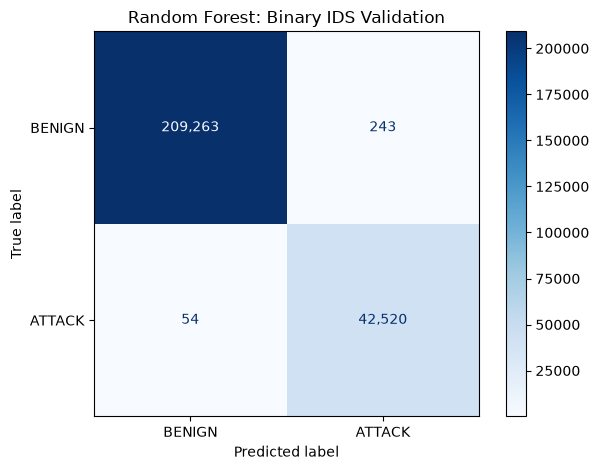

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    rf_val_pred,
    labels=[0, 1],
    display_labels=["BENIGN", "ATTACK"],
    cmap="Blues",
    values_format=","
)

plt.title("Random Forest: Binary IDS Validation")
plt.tight_layout()
plt.show()

In [35]:

from xgboost import XGBClassifier
import time

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

start_time = time.perf_counter()

xgb_model.fit(X_train, y_train)

xgb_training_time = time.perf_counter() - start_time

print(f"XGBoost training time: {xgb_training_time:.2f} seconds")
print("XGBoost training completed.")


XGBoost training time: 22.22 seconds
XGBoost training completed.


In [36]:

xgb_val_pred = xgb_model.predict(X_val)
xgb_val_prob = xgb_model.predict_proba(X_val)[:, 1]

xgb_metrics = {
    "Accuracy": accuracy_score(y_val, xgb_val_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_val, xgb_val_pred),
    "Precision": precision_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "F1-score": f1_score(
        y_val, xgb_val_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_val, xgb_val_prob),
    "PR-AUC": average_precision_score(y_val, xgb_val_prob),
    "Training Time (seconds)": xgb_training_time
}

for metric, value in xgb_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_val,
    xgb_val_pred,
    labels=[0, 1],
    target_names=["BENIGN", "ATTACK"],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_val, xgb_val_pred, labels=[0, 1]))


Accuracy: 0.9990
Balanced Accuracy: 0.9993
Precision: 0.9946
Recall: 0.9998
F1-score: 0.9972
ROC-AUC: 1.0000
PR-AUC: 0.9999
Training Time (seconds): 22.2222

Classification report:
              precision    recall  f1-score   support

      BENIGN     1.0000    0.9989    0.9994    209506
      ATTACK     0.9946    0.9998    0.9972     42574

    accuracy                         0.9990    252080
   macro avg     0.9973    0.9993    0.9983    252080
weighted avg     0.9990    0.9990    0.9990    252080

Confusion matrix:
[[209274    232]
 [     9  42565]]


In [37]:

from pathlib import Path
import json
import joblib
import pandas as pd
from datetime import datetime, timezone

BINARY_MODEL_DIR = PROJECT_ROOT / "models" / "binary"
METRICS_DIR = PROJECT_ROOT / "outputs" / "metrics"

BINARY_MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Binary model directory:", BINARY_MODEL_DIR)
print("Metrics directory:", METRICS_DIR)


Binary model directory: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary
Metrics directory: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics


In [38]:

comparison_df = pd.DataFrame({
    "Random Forest": rf_metrics,
    "XGBoost": xgb_metrics
})

display(comparison_df.round(5))

comparison_path = METRICS_DIR / "binary_validation_comparison.csv"
comparison_df.to_csv(comparison_path)

print("Saved:", comparison_path)


,Random Forest,XGBoost
Accuracy,0.99882,0.99904
Balanced Accuracy,0.99879,0.99934
Precision,0.99432,0.99458
Recall,0.99873,0.99979
F1-score,0.99652,0.99718
ROC-AUC,0.99977,0.99998
PR-AUC (Average Precision),0.99789,NaN
Training Time (seconds),89.93515,22.22223
PR-AUC,NaN,0.99988


Saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\binary_validation_comparison.csv


In [39]:

binary_label_mapping = {
    0: "BENIGN",
    1: "ATTACK"
}

training_metadata = {
    "dataset": "CIC-IDS2017",
    "task": "Binary intrusion detection",
    "target_definition": "BENIGN versus all non-BENIGN attack classes",
    "training_rows": int(len(y_train)),
    "validation_rows": int(len(y_val)),
    "feature_count": int(len(FEATURE_COLUMNS)),
    "training_date_utc": datetime.now(timezone.utc).isoformat(),
    "random_state": 42,
    "validation_split": "Saved stratified validation indices",
}

rf_bundle = {
    "model": rf_model,
    "feature_columns": FEATURE_COLUMNS,
    "label_mapping": binary_label_mapping,
    "metadata": training_metadata,
    "validation_metrics": {
        key: float(value) for key, value in rf_metrics.items()
    },
}

xgb_bundle = {
    "model": xgb_model,
    "feature_columns": FEATURE_COLUMNS,
    "label_mapping": binary_label_mapping,
    "metadata": {
        **training_metadata,
        "selected_candidate": True,
        "selection_reason": (
            "Better validation recall, F1, balanced accuracy "
            "and training time than Random Forest"
        ),
    },
    "validation_metrics": {
        key: float(value) for key, value in xgb_metrics.items()
    },
}

rf_path = BINARY_MODEL_DIR / "random_forest_binary_bundle.joblib"
xgb_path = BINARY_MODEL_DIR / "xgboost_binary_bundle.joblib"

joblib.dump(rf_bundle, rf_path, compress=3)
joblib.dump(xgb_bundle, xgb_path, compress=3)

print("Random Forest bundle saved:", rf_path)
print("XGBoost bundle saved:", xgb_path)


Random Forest bundle saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\random_forest_binary_bundle.joblib
XGBoost bundle saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\models\binary\xgboost_binary_bundle.joblib


In [40]:

loaded_bundle = joblib.load(xgb_path)

assert hasattr(loaded_bundle["model"], "predict")
assert hasattr(loaded_bundle["model"], "predict_proba")
assert len(loaded_bundle["feature_columns"]) == 78
assert loaded_bundle["label_mapping"] == {
    0: "BENIGN",
    1: "ATTACK"
}

print("Model bundle verification: PASS")
print("Feature count:", len(loaded_bundle["feature_columns"]))
print("Label mapping:", loaded_bundle["label_mapping"])
print("Model type:", type(loaded_bundle["model"]).__name__)


Model bundle verification: PASS
Feature count: 78
Label mapping: {0: 'BENIGN', 1: 'ATTACK'}
Model type: XGBClassifier


In [44]:

import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_val, xgb_val_prob)
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1] + recall_values[:-1] + 1e-12
    )
)

best_index = int(np.argmax(f1_values))
best_threshold = float(thresholds[best_index])

# Evaluate the default threshold
default_predictions = (xgb_val_prob >= 0.5).astype(np.int8)

print("DEFAULT THRESHOLD: 0.50")
print("Precision:", round(
    precision_score(y_val, default_predictions), 5
))
print("Recall:", round(
    recall_score(y_val, default_predictions), 5
))
print("F1-score:", round(
    f1_score(y_val, default_predictions), 5
))
print("Confusion matrix:")
print(confusion_matrix(y_val, default_predictions))

# Evaluate the best threshold for validation F1
best_predictions = (
    xgb_val_prob >= best_threshold
).astype(np.int8)

print("\nBEST VALIDATION F1 THRESHOLD")
print("Threshold:", round(best_threshold, 5))
print("Precision:", round(
    precision_score(y_val, best_predictions), 5
))
print("Recall:", round(
    recall_score(y_val, best_predictions), 5
))
print("F1-score:", round(
    f1_score(y_val, best_predictions), 5
))
print("Confusion matrix:")
print(confusion_matrix(y_val, best_predictions))


DEFAULT THRESHOLD: 0.50
Precision: 0.99458
Recall: 0.99979
F1-score: 0.99718
Confusion matrix:
[[209274    232]
 [     9  42565]]

BEST VALIDATION F1 THRESHOLD
Threshold: 0.843
Precision: 0.99651
Recall: 0.99876
F1-score: 0.99763
Confusion matrix:
[[209357    149]
 [    53  42521]]


In [45]:

# Freeze the binary IDS operating threshold using validation results.
SELECTED_THRESHOLD = 0.50

threshold_decision = {
    "selected_threshold": SELECTED_THRESHOLD,
    "selection_basis": "Prioritize attack recall",
    "validation_attack_recall": float(
        recall_score(y_val, default_predictions)
    ),
    "validation_attack_precision": float(
        precision_score(y_val, default_predictions)
    ),
    "validation_attack_f1": float(
        f1_score(y_val, default_predictions)
    ),
    "validation_false_positives": int(
        confusion_matrix(y_val, default_predictions)[0, 1]
    ),
    "validation_false_negatives": int(
        confusion_matrix(y_val, default_predictions)[1, 0]
    ),
}

threshold_path = METRICS_DIR / "binary_threshold_decision.json"

with open(threshold_path, "w", encoding="utf-8") as f:
    json.dump(threshold_decision, f, indent=4)

print("Threshold decision saved:", threshold_path)
print(json.dumps(threshold_decision, indent=4))


Threshold decision saved: c:\Users\LENOVO\Desktop\Hybrid IDS\H-IDS\outputs\metrics\binary_threshold_decision.json
{
    "selected_threshold": 0.5,
    "selection_basis": "Prioritize attack recall",
    "validation_attack_recall": 0.9997886033729506,
    "validation_attack_precision": 0.994579059279856,
    "validation_attack_f1": 0.9971770273277811,
    "validation_false_positives": 232,
    "validation_false_negatives": 9
}


In [46]:
import json
from pathlib import Path

threshold_path = METRICS_DIR / "binary_threshold_decision.json"

assert threshold_path.exists(), (
    f"Threshold decision file not found: {threshold_path}"
)

with open(threshold_path, "r", encoding="utf-8") as f:
    threshold_config = json.load(f)

print("THRESHOLD CONFIGURATION")
print("=" * 50)

print(json.dumps(threshold_config, indent=4))

selected_threshold = float(
    threshold_config["selected_threshold"]
)

assert 0.0 < selected_threshold < 1.0

print("\nThreshold verification: PASS")
print("Selected threshold:", selected_threshold)

THRESHOLD CONFIGURATION
{
    "selected_threshold": 0.5,
    "selection_basis": "Prioritize attack recall",
    "validation_attack_recall": 0.9997886033729506,
    "validation_attack_precision": 0.994579059279856,
    "validation_attack_f1": 0.9971770273277811,
    "validation_false_positives": 232,
    "validation_false_negatives": 9
}

Threshold verification: PASS
Selected threshold: 0.5
